# 5. Animation and Online-Fading Robustness Evaluation

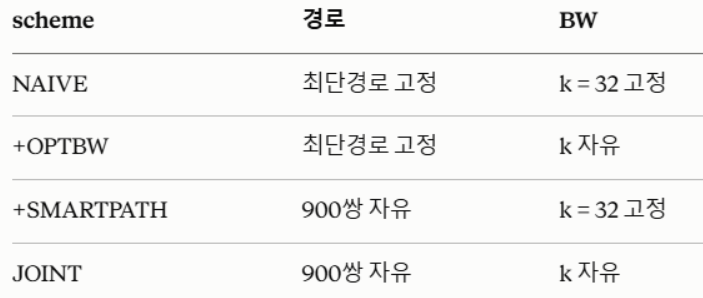

## 0. Import 및 애니메이션 설정

In [ ]:
import importlib

import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Video, display
from matplotlib.animation import FFMpegWriter, FuncAnimation, PillowWriter
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Circle, Rectangle

import project_config

importlib.reload(project_config)

from project_config import (
    DF_HZ,
    N_SC,
    OBSTACLES,
    ROOM_X,
    ROOM_Y,
    FINGERPRINT_PATH,
    PATH_PLANNING_RESULTS_PATH,
    FIGURES_DIR,
    ANIMATIONS_DIR,
    RANDOM_SEED,
)


In [ ]:
import imageio_ffmpeg

FFMPEG_EXE = imageio_ffmpeg.get_ffmpeg_exe()

# matplotlib이 imageio-ffmpeg의 실행 파일을 사용하도록 지정
plt.rcParams["animation.ffmpeg_path"] = FFMPEG_EXE


FPS = 10

if animation.writers.is_available("ffmpeg"):
    ANIM_BACKEND = "ffmpeg"
    ANIM_EXT = ".mp4"
    FRAME_STRIDE = 2
else:
    ANIM_BACKEND = "pillow"
    ANIM_EXT = ".gif"
    FRAME_STRIDE = 3


def make_writer():
    if ANIM_BACKEND == "ffmpeg":
        return FFMpegWriter(fps=FPS, bitrate=2400)
    return PillowWriter(fps=FPS)


print("ffmpeg 경로:", FFMPEG_EXE)
print(f"animation: {ANIM_BACKEND}, {FPS} fps, stride={FRAME_STRIDE}")

## 0. `fingerprint.npz`와 `path_planning_results.npz` 불러오기

In [ ]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ANIMATIONS_DIR.mkdir(parents=True, exist_ok=True)

if not FINGERPRINT_PATH.exists():
    raise FileNotFoundError(FINGERPRINT_PATH)
if not PATH_PLANNING_RESULTS_PATH.exists():
    raise FileNotFoundError(PATH_PLANNING_RESULTS_PATH)


with np.load(FINGERPRINT_PATH, allow_pickle=False) as fp:
    snr_db = fp["snr_db"]


SCHEME_PREFIXES = {
    "NAIVE": "naive",
    "+OPTBW": "optbw",
    "+SMARTPATH": "smartpath",
    "JOINT": "joint",
}

SCHEME_INFO = {
    "NAIVE": ("Shortest", "Equal"),
    "+OPTBW": ("Shortest", "Opt"),
    "+SMARTPATH": ("Comm-aware", "Equal"),
    "JOINT": ("Comm-aware", "Opt"),
}

SCHEME_ORDER = ("NAIVE", "+OPTBW", "+SMARTPATH", "JOINT")

ARRAY_KEYS = (
    "time_s",
    "pos1_xy",
    "pos2_xy",
    "split_k",
    "rate1_bps",
    "rate2_bps",
    "min_rate_bps",
    "snr1_sc",
    "snr2_sc",
)

SCALAR_KEYS = (
    "r_min_bps",
    "mission_time_s",
)


RESULTS = {}

with np.load(PATH_PLANNING_RESULTS_PATH, allow_pickle=False) as data:
    for scheme, prefix in SCHEME_PREFIXES.items():
        result = {
            key: data[f"{prefix}_{key}"]
            for key in ARRAY_KEYS
        }
        result.update({
            key: float(data[f"{prefix}_{key}"].item())
            for key in SCALAR_KEYS
        })

        n_time = len(result["time_s"])
        frames = np.arange(0, n_time, FRAME_STRIDE, dtype=int)
        if frames[-1] != n_time - 1:
            frames = np.append(frames, n_time - 1)

        result["frames"] = frames
        RESULTS[scheme] = result


print(f"SNR heatmap shape: {snr_db.shape}")
print("scheme         R_min [Mbps]    T [s]    frames")

for scheme in SCHEME_ORDER:
    result = RESULTS[scheme]
    print(
        f"{scheme:<12} "
        f"{result['r_min_bps']/1e6:12.2f} "
        f"{result['mission_time_s']:8.2f} "
        f"{len(result['frames']):8d}"
    )

## 1. 애니메이션 공통 설정

In [ ]:
SNR_VMIN = float(snr_db.min())   # snr 최솟값
SNR_VMAX = float(snr_db.max())   # snr 최댓값

AMR1_COLOR = "tab:blue"     # AMR1: 파란색
AMR2_COLOR = "tab:orange"   # AMR2: 주황색


# =========================================================
# heatmap 위에 obstacle 12개의 윤곽선 그리는 함수
# =========================================================
def draw_obstacles(ax):
    for obs in OBSTACLES:
        cx, cy = obs["center"]
        edge_color = "white" if obs["material"] == "concrete" else "yellow"

        if obs["kind"] == "box":
            dx, dy = obs["size"][:2]
            patch = Rectangle(
                (cx - dx / 2, cy - dy / 2),
                dx,
                dy,
                fill=False,
                edgecolor=edge_color,
                linewidth=1.4,
                zorder=3,
            )
        else:
            patch = Circle(
                (cx, cy),
                obs["radius"],
                fill=False,
                edgecolor=edge_color,
                linewidth=1.4,
                zorder=3,
            )

        ax.add_patch(patch)


# =========================================================
# 저장된 animation을 노트북 화면에 display하는 함수
# =========================================================
def display_animation(path):
    if path.suffix == ".mp4":
        display(Video(str(path), embed=True, width=900))
    else:
        display(Image(filename=str(path)))


# =========================================================
# 실제 animation 만드는 함수
# =========================================================
def build_animation(scheme, out_path, show_k_track=False):
    result = RESULTS[scheme]

    time_s = result["time_s"]           # 시뮬레이션 시간
    pos1 = result["pos1_xy"]            # 시간별 AMR1 위치
    pos2 = result["pos2_xy"]            # 시간별 AMR2 위치
    split_k = result["split_k"]         # 시간별 subcarrier 분할 위치
    rate1 = result["rate1_bps"] / 1e6   # 전송률
    rate2 = result["rate2_bps"] / 1e6   # 전송률
    rmin = result["min_rate_bps"] / 1e6 # 최소 전송률
    frames = result["frames"]

    path_kind, bw_kind = SCHEME_INFO[scheme]   # 어떤 경로인지, 어떤 BW 분할 방식을 쓰는지
    n_right = 4 if show_k_track else 3         # 몇 개의 pannel을 만들지

    # 전체 그림 구성
    fig = plt.figure(figsize=(14, 6.5))
    gs = GridSpec(
        n_right,
        2,
        width_ratios=[2.0, 1.15],
        hspace=0.55,
        wspace=0.30,
        figure=fig,
    )


    # 왼쪽: SNR heatmap과 AMR 이동
    ax_map = fig.add_subplot(gs[:, 0])
    im = ax_map.imshow(
        snr_db,
        origin="lower",
        extent=[0, ROOM_X, 0, ROOM_Y],
        cmap="turbo",
        aspect="equal",
        vmin=SNR_VMIN,
        vmax=SNR_VMAX,
        zorder=1,
    )
    fig.colorbar(
        im,
        ax=ax_map,
        fraction=0.028,
        pad=0.02,
        label="Mean SISO SNR [dB]",
    )
    draw_obstacles(ax_map)

    # 계획된 전체 경로는 옅게, 지나온 경로는 진하게 표시
    ax_map.plot(pos1[:, 0], pos1[:, 1], color=AMR1_COLOR, alpha=0.25, linewidth=1.0)
    ax_map.plot(pos2[:, 0], pos2[:, 1], color=AMR2_COLOR, alpha=0.25, linewidth=1.0)

    trail1, = ax_map.plot([], [], color=AMR1_COLOR, alpha=0.80, linewidth=2.6)
    trail2, = ax_map.plot([], [], color=AMR2_COLOR, alpha=0.80, linewidth=2.6)

    dot1, = ax_map.plot(
        [], [], "o", color=AMR1_COLOR, markersize=13,
        markeredgecolor="white", markeredgewidth=1.8, label="AMR1",
    )
    dot2, = ax_map.plot(
        [], [], "o", color=AMR2_COLOR, markersize=13,
        markeredgecolor="white", markeredgewidth=1.8, label="AMR2",
    )

    ax_map.set(
        xlim=(0, ROOM_X),
        ylim=(0, ROOM_Y),
        xlabel="x [m]",
        ylabel="y [m]",
        title=f"{scheme}: {path_kind} path + {bw_kind}-BW (SISO)",
    )
    ax_map.legend(loc="upper left", fontsize=9)


    # 오른쪽 1: R_min(t)
    ax_rate = fig.add_subplot(gs[0, 1])
    ax_rate.plot(time_s, rmin, color="tab:green", linewidth=1.8)
    cursor = ax_rate.axvline(time_s[0], color="black", linewidth=1.4)
    cursor_dot, = ax_rate.plot([], [], "o", color="black", markersize=7)

    ax_rate.set(
        xlim=(0, time_s[-1]),
        ylim=(0, rmin.max() * 1.15),
        ylabel=r"$R_{min}(t)$ [Mbps]",
    )
    ax_rate.tick_params(labelbottom=False)
    ax_rate.grid(alpha=0.25)


    # 오른쪽 2: BW allocation bar
    ax_bw = fig.add_subplot(gs[1, 1])
    bar1 = ax_bw.barh(0, split_k[0], color=AMR1_COLOR, height=0.6)[0]
    bar2 = ax_bw.barh(
        0,
        N_SC - split_k[0],
        left=split_k[0],
        color=AMR2_COLOR,
        height=0.6,
    )[0]
    bw_label = ax_bw.text(
        N_SC / 2,
        -0.62,
        "",
        ha="center",
        va="top",
        fontsize=9,
        family="monospace",
    )

    ax_bw.set(
        xlim=(0, N_SC),
        ylim=(-0.9, 0.5),
        xlabel="Subcarrier index",
        title="BW allocation",
    )
    ax_bw.set_yticks([])

    # 오른쪽 3: k*(t)의 변화
    if show_k_track:
        ax_k = fig.add_subplot(gs[2, 1])
        ax_k.plot(time_s, split_k, color="tab:purple", linewidth=1.6)
        ax_k.axhline(N_SC // 2, color="gray", linestyle=":", linewidth=1.2)
        k_cursor = ax_k.axvline(time_s[0], color="black", linewidth=1.4)
        k_dot, = ax_k.plot([], [], "o", color="tab:purple", markersize=7)

        ax_k.set(
            xlim=(0, time_s[-1]),
            ylim=(0, N_SC),
            xlabel="Time [s]",
            ylabel=r"$k^\star(t)$",
        )
        ax_k.grid(alpha=0.25)
    else:
        k_cursor = None
        k_dot = None

    # 오른쪽 4: 현재 수치
    ax_text = fig.add_subplot(gs[n_right - 1, 1])
    ax_text.axis("off")
    overlay = ax_text.text(
        0.0,
        0.95,
        "",
        transform=ax_text.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        family="monospace",
        bbox={
            "facecolor": "white",
            "edgecolor": "gray",
            "boxstyle": "round,pad=0.5",
        },
    )


    def update(t):
        trail1.set_data(pos1[:t + 1, 0], pos1[:t + 1, 1])
        trail2.set_data(pos2[:t + 1, 0], pos2[:t + 1, 1])
        dot1.set_data([pos1[t, 0]], [pos1[t, 1]])
        dot2.set_data([pos2[t, 0]], [pos2[t, 1]])

        cursor.set_xdata([time_s[t], time_s[t]])
        cursor_dot.set_data([time_s[t]], [rmin[t]])

        k = int(split_k[t])
        bar1.set_width(k)
        bar2.set_x(k)
        bar2.set_width(N_SC - k)
        bw_label.set_text(f"AMR1 {k:2d} sc | AMR2 {N_SC-k:2d} sc")

        if k_cursor is not None:
            k_cursor.set_xdata([time_s[t], time_s[t]])
            k_dot.set_data([time_s[t]], [split_k[t]])

        overlay.set_text(
            f"t     = {time_s[t]:6.2f} s\n"
            f"R1    = {rate1[t]:6.2f} Mbps\n"
            f"R2    = {rate2[t]:6.2f} Mbps\n"
            f"R_min = {rmin[t]:6.2f} Mbps\n"
            f"k*    = {k:6d}"
        )

        return ()

    ani = FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=1000 // FPS,
        blit=False,
    )
    ani.save(str(out_path), writer=make_writer())
    plt.close(fig)

    duration = len(frames) / FPS
    print(f"저장 완료: {out_path.name} ({duration:.1f} s)")

    return ani

## 2. T5.1 - NAIVE 애니메이션

In [ ]:
NAIVE_ANIM_PATH = ANIMATIONS_DIR / f"14_naive_animation{ANIM_EXT}"

naive_ani = build_animation(
    scheme="NAIVE",
    out_path=NAIVE_ANIM_PATH,
    show_k_track=False,
)

display_animation(NAIVE_ANIM_PATH)

## 3. T5.2 - JOINT 애니메이션

In [ ]:
JOINT_ANIM_PATH = ANIMATIONS_DIR / f"15_joint_animation{ANIM_EXT}"

joint_ani = build_animation(
    scheme="JOINT",
    out_path=JOINT_ANIM_PATH,
    show_k_track=True,
)

display_animation(JOINT_ANIM_PATH)

## 4. T5.3 - Rayleigh fading online replay
Offline SNR에 Rayleigh fading 추가

In [ ]:
N_REALIZATIONS = 30   # Rayleigh fading 환경을 30번 만들어서 실험


# =========================================================
# offline에서 만든 한 scheme을 30개의 Rayleigh fading 환경에서 다시 재생하는 함수
# =========================================================
def replay_online(snr1_sc, snr2_sc, split_k, rng):
    n_time = len(split_k)   # 전체 시간 길이
    sc_index = np.arange(N_SC)[None, :]   # subcarrier 번호 생성

    # offline에서 정한 subcarrier 경계를 그대로 유지
    mask1 = sc_index < split_k[:, None]

    # Rayleigh fading 생성
    # g ~ CN(0, 1), 따라서 |g|^2 ~ Exp(1)
    shape = (N_REALIZATIONS, n_time, N_SC)
    g = (
        rng.standard_normal(shape)
        + 1j * rng.standard_normal(shape)
    ) / np.sqrt(2.0)

    fading_power = np.abs(g) ** 2   # fading power

    snr1_online = snr1_sc[None, :, :] * fading_power   # Offline SNR에 fading power 적용
    snr2_online = snr2_sc[None, :, :] * fading_power   # Offline SNR에 fading power 적용

    # online AMR1의 전송률
    rate1_online = DF_HZ * (
        np.log2(1.0 + snr1_online) * mask1
    ).sum(axis=2)

    # online AMR2의 전송률
    rate2_online = DF_HZ * (
        np.log2(1.0 + snr2_online) * ~mask1
    ).sum(axis=2)

    # 시간별 bottleneck throughput: 더 낮은 전송률
    min_rate_online = np.minimum(rate1_online, rate2_online)

    return {
        "min_rate_online": min_rate_online,
        "mean_trace": min_rate_online.mean(axis=0),
        "std_trace": min_rate_online.std(axis=0),
        "r_min_online": min_rate_online.min(axis=1),
    }



# =========================================================
# replay_online을 scheme 4개에 대해서 실행 + 기존의 offline R_min과 비교
# =========================================================
rng = np.random.default_rng(RANDOM_SEED)
ONLINE = {}

for scheme in SCHEME_ORDER:
    result = RESULTS[scheme]
    online = replay_online(
        result["snr1_sc"],
        result["snr2_sc"],
        result["split_k"],
        rng,
    )

    # offline-to-online ratio
    online["ratio"] = float(
        online["r_min_online"].mean()
        / result["r_min_bps"]
    )

    ONLINE[scheme] = online


print(f"N_realizations = {N_REALIZATIONS}")
print("scheme         offline R_min   online R_min    ratio")
print("                   [Mbps]       mean [Mbps]")

for scheme in SCHEME_ORDER:
    result = RESULTS[scheme]
    online = ONLINE[scheme]

    print(
        f"{scheme:<12} "
        f"{result['r_min_bps']/1e6:13.2f} "
        f"{online['r_min_online'].mean()/1e6:14.2f} "
        f"{online['ratio']:8.3f}"
    )

## 5. T5.3 - `13_offline_vs_online.png` 생성

In [ ]:
# 색상 설정
OFFLINE_COLOR = "tab:green"
ONLINE_COLOR = "tab:blue"

# 4개의 subplot 생성
fig, axes = plt.subplots(
    len(SCHEME_ORDER),
    1,
    figsize=(11, 9.5),
)


# =========================================================
# scheme별로 plot하기
# =========================================================
for ax, scheme in zip(axes, SCHEME_ORDER):
    result = RESULTS[scheme]   # offline
    online = ONLINE[scheme]    # onine

    time_s = result["time_s"]   # 시간축
    offline_trace = result["min_rate_bps"] / 1e6
    online_mean = online["mean_trace"] / 1e6
    online_std = online["std_trace"] / 1e6

    lower = np.maximum(online_mean - online_std, 0.0)
    upper = online_mean + online_std

    ax.fill_between(
        time_s,
        lower,
        upper,
        color=ONLINE_COLOR,
        alpha=0.25,
        linewidth=0,
        label=r"online $\pm1\sigma$",
    )
    ax.plot(
        time_s,
        offline_trace,
        color=OFFLINE_COLOR,
        linewidth=1.8,
        label="offline",
    )
    ax.plot(
        time_s,
        online_mean,
        color=ONLINE_COLOR,
        linewidth=1.8,
        label="online mean",
    )

    path_kind, bw_kind = SCHEME_INFO[scheme]
    ax.set(
        xlim=(0, time_s[-1]),
        ylim=(0, max(offline_trace.max(), upper.max()) * 1.20),
        ylabel=r"$R_{min}(t)$ [Mbps]",
        title=f"{scheme} ({path_kind}, {bw_kind}-BW)",
    )
    ax.grid(alpha=0.25)

    ax.text(
        0.99,
        0.92,
        f"offline-to-online ratio = {online['ratio']:.3f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox={
            "facecolor": "white",
            "edgecolor": "gray",
            "alpha": 0.9,
            "boxstyle": "round,pad=0.35",
        },
    )

axes[0].legend(loc="upper left", ncol=3, fontsize=9)
axes[-1].set_xlabel("Time [s]")

fig.suptitle(
    "Offline vs Online Rayleigh Fading",
    fontsize=13,
    y=0.995,
)
fig.tight_layout()

ROBUSTNESS_PATH = FIGURES_DIR / "13_offline_vs_online.png"
fig.savefig(ROBUSTNESS_PATH, dpi=300, bbox_inches="tight")
plt.show()

print("저장 완료:", ROBUSTNESS_PATH)

## 6. T5.3 질문 답변용 결과
ratio 비율이 1에서 크게 달라질수록 fragile함

In [ ]:
naive_ratio = ONLINE["NAIVE"]["ratio"]
joint_ratio = ONLINE["JOINT"]["ratio"]

print("[Offline-to-online ratio]")
for scheme in SCHEME_ORDER:
    print(f"{scheme:<12}: {ONLINE[scheme]['ratio']:.3f}")

print()
if joint_ratio < naive_ratio:
    print(
        f"JOINT의 ratio({joint_ratio:.3f})가 "
        f"NAIVE({naive_ratio:.3f})보다 낮으므로, "
        "이번 결과에서는 JOINT가 더 fragile하다."
    )
else:
    print(
        f"JOINT의 ratio({joint_ratio:.3f})가 "
        f"NAIVE({naive_ratio:.3f})보다 낮지 않으므로, "
        "이번 결과에서는 JOINT가 더 fragile하다고 볼 수 없다."
    )